In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ROOT = Path(r"D:\Upenn\Large-scaleML\result")

DISEASES = {
    "cihd_pmbb": "CIHD",
    "ckd_pmbb": "CKD",
    "hypothyroidism_pmbb": "Hypothyroidism",
    "t2d_pmbb": "T2D",
}
RACES = ["Black or African American", "White"]
RACE_LABEL = {"Black or African American": "Black", "White": "White"}
SPLITS = ["train", "val", "test"]

RACE_COLOR = {"Black or African American": "#2a78d6", "White": "#eb6834"}
SPLIT_SHADES = {
    "Black or African American": {"train": "#1c5cab", "val": "#5598e7", "test": "#9ec5f4"},
    "White": {"train": "#b8481c", "val": "#f08c62", "test": "#f7bfa6"},
}
SPLIT_MARKER = {"train": "o", "val": "s", "test": "^"}
INK, INK2, GRID = "#1f1f1e", "#5f5e58", "#e4e3de"

In [2]:
frames = []
for folder, label in DISEASES.items():
    d = pd.read_csv(ROOT / folder / "split_summary.csv")
    d["disease"] = label
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
df["split"] = pd.Categorical(df["split"], SPLITS, ordered=True)
diseases = list(DISEASES.values())
df

,split,race,n,n_case,case_rate_pct,disease
0,train,Black or African American,4611,85,1.84,CIHD
1,train,White,11384,261,2.29,CIHD
2,val,Black or African American,988,18,1.82,CIHD
3,val,White,2440,56,2.30,CIHD
4,test,Black or African American,988,18,1.82,CIHD
5,test,White,2440,56,2.30,CIHD
6,train,Black or African American,4746,141,2.97,CKD
7,train,White,13718,216,1.57,CKD
8,val,Black or African American,1017,31,3.05,CKD
9,val,White,2940,47,1.60,CKD


In [3]:
tot = df.groupby(["disease", "race"])[["n", "n_case"]].sum()
tot["rate_pct"] = (100 * tot["n_case"] / tot["n"]).round(2)
ratio = (tot.xs(RACES[0], level="race")["rate_pct"] / tot.xs(RACES[1], level="race")["rate_pct"]).round(2)

print(tot)
print("\nBlack / White case-rate ratio:\n", ratio)

                                              n  n_case  rate_pct
disease        race                                              
CIHD           Black or African American   6587     121      1.84
               White                      16264     373      2.29
CKD            Black or African American   6780     202      2.98
               White                      19598     309      1.58
Hypothyroidism Black or African American   7769      65      0.84
               White                      17960     330      1.84
T2D            Black or African American   5689     221      3.88
               White                      18216     305      1.67

Black / White case-rate ratio:
 disease
CIHD              0.80
CKD               1.89
Hypothyroidism    0.46
T2D               2.32
Name: rate_pct, dtype: float64


In [7]:
n_arr = (df.pivot_table(index="disease", columns=["race", "split"], values="n", observed=False)
           .reindex(index=diseases))
case_arr = (df.pivot_table(index="disease", columns=["race", "split"], values="n_case", observed=False)
              .reindex(index=diseases))
rate_arr = (df.pivot_table(index="disease", columns=["race", "split"], values="case_rate_pct", observed=False)
              .reindex(index=diseases))

x = np.arange(len(diseases))
w = 0.36

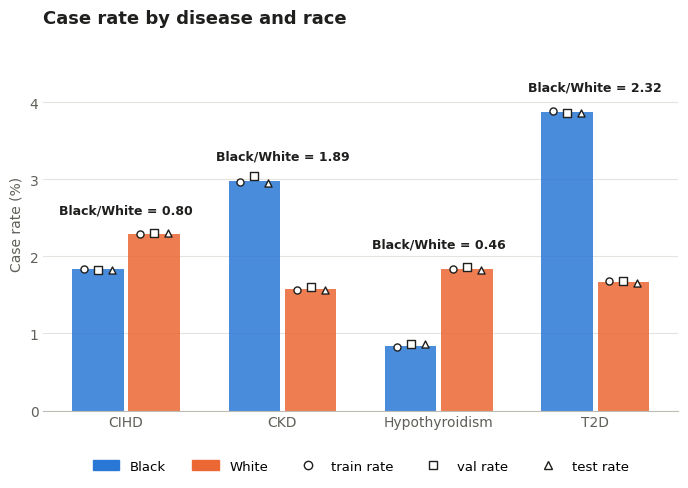

In [11]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
fig, ax = plt.subplots(figsize=(7, 5))

top = tot["rate_pct"].max()

for j, race in enumerate(RACES):
    xpos = x + (j - 0.5) * w
    overall = tot.xs(race, level="race").reindex(diseases)["rate_pct"].to_numpy()
    ax.bar(xpos, overall, width=w - 0.03, color=RACE_COLOR[race], alpha=0.85)
    for k, split in enumerate(SPLITS):
        ax.scatter(xpos + (k - 1) * 0.09, rate_arr[(race, split)].to_numpy(),
                   marker=SPLIT_MARKER[split], s=26, color="white",
                   edgecolor=INK, linewidth=1, zorder=3)

for xi, d in zip(x, diseases):
    hi = tot.loc[d, "rate_pct"].max()
    ax.text(xi, hi + top * 0.07, f"Black/White = {ratio[d]:.2f}", ha="center",
            fontsize=9, color=INK, fontweight="bold")

ax.set_xticks(x, diseases)
ax.set_ylim(0, top * 1.25)
ax.set_ylabel("Case rate (%)", color=INK2)
ax.set_title("Case rate by disease and race", loc="left",
             fontsize=13, color=INK, fontweight="bold", pad=10)

ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#bdbcb5")
ax.tick_params(colors=INK2, length=0)

handles = (
    [Patch(color=RACE_COLOR[r], label=RACE_LABEL[r]) for r in RACES]
    + [Line2D([], [], marker=SPLIT_MARKER[s], ls="", mfc="white", mec=INK, label=f"{s} rate")
       for s in SPLITS]
)
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.1),
          ncol=5, frameon=False, fontsize=9.5)

fig.tight_layout()
plt.show()